#Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

# Load and Inspect the Data

In [2]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")

display(movies.head())
display(ratings.head())
print("Users:", ratings["user_id"].nunique())
print("Movies:", ratings["movie_id"].nunique())
print("Ratings:", len(ratings))

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120


###What does one row in movies represent?
A unique movie title with its associated genre metadata.

###What does one row in ratings represent?
An explicit rating given by a specific user to a movie at a given timestamp.

###How many unique users and movies are present?
12 unique users and 20 unique movies.

###What type of feedback is the rating column?
Explicit feedback.

###What is the rating scale?
Integer ratings from 1 to 5.

#Inspect Rating Behaviour

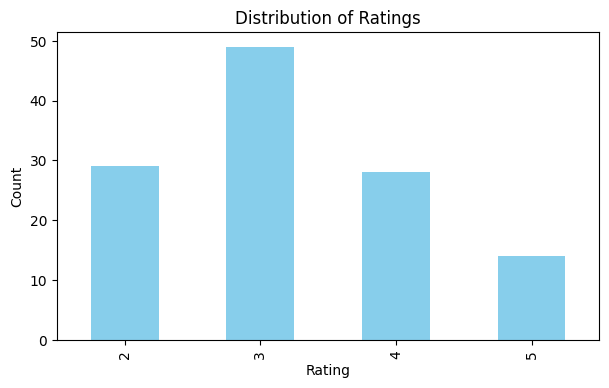

In [4]:
ratings["rating"].value_counts().sort_index()
plt.figure(figsize=(7,4))
ratings["rating"].value_counts().sort_index().plot(kind="bar", color="skyblue")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

Ratings are heavily skewed toward positive scores (3, 4, and 5), with very few 1-star or 2-star ratings.

This positive class imbalance means models may naturally predict higher ratings, which can inflate apparent accuracy but make distinguishing genuinely poor items harder.

#Create a Train/Test Split

In [5]:
ratings = ratings.sort_values(["user_id", "timestamp"])
test = ratings.groupby("user_id").tail(1).copy()
train = ratings.drop(test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))
display(test.head())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


Sorting by timestamp ensures that evaluation tests future interactions against past behavior, preventing data leakage

##Popularity Baseline & Rating Evaluation

In [6]:
global_mean = train["rating"].mean()
movie_stats = (
    train.groupby("movie_id")
    .agg(mean_rating=("rating", "mean"), rating_count=("rating", "size"))
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id")
)

movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()
baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map).fillna(global_mean)

def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(baseline_test["rating"], baseline_test["prediction"])
print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


##Content-Based Filtering

In [7]:
genre_features = movies["genres"].str.get_dummies(sep="|")
content_items = pd.concat([movies[["movie_id", "title"]], genre_features], axis=1)
genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movie_id")[genre_columns]

def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values
    return (features * ratings_array).mean(axis=0)

def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)
    sim = cosine_similarity(profile, item_vec)[0, 0]
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train), axis=1
)
content_mae, content_rmse = rating_metrics(content_test["rating"], content_test["prediction"])
print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


##Item-Based Collaborative Filtering & Model Comparison

In [8]:
user_item = train.pivot_table(index="user_id", columns="movie_id", values="rating")
item_user = user_item.T.fillna(0)
item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=user_item.columns,
    columns=user_item.columns
)

def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    weighted_sum = 0.0
    similarity_sum = 0.0
    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]
            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim
    if similarity_sum == 0:
        return global_mean
    return weighted_sum / similarity_sum

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train), axis=1
)
cf_mae, cf_rmse = rating_metrics(cf_test["rating"], cf_test["prediction"])
print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))

rating_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})
display(rating_results.sort_values("MAE"))

CF MAE: 0.924
CF RMSE: 1.07


,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701


##Top-N Ranking, Coverage, Novelty, and Diversity

In [9]:
TOP_K = 3
test["relevant"] = test["rating"] >= 4
all_movie_ids = movies["movie_id"].tolist()

def unseen_movies(user_id):
    seen = set(train.loc[train["user_id"] == user_id, "movie_id"])
    return [m for m in all_movie_ids if m not in seen]

popularity_order = movie_stats.sort_values(["mean_rating", "rating_count"], ascending=[False, False])["movie_id"].tolist()

def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def precision_recall_at_k(recs, relevant, k):
    hits = len(set(recs) & set(relevant))
    return hits / k, (hits / len(relevant) if relevant else np.nan)

def ndcg_at_k(recs, relevant, k):
    dcg = sum(1 / np.log2(rank + 1) for rank, m in enumerate(recs[:k], start=1) if m in relevant)
    idcg = sum(1 / np.log2(rank + 1) for rank in range(1, min(len(relevant), k) + 1))
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=3):
    rows = []
    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[(test["user_id"] == user_id) & (test["rating"] >= 4), "movie_id"].tolist()
        if not relevant: continue
        recs = recommender(user_id, k)
        p, r = precision_recall_at_k(recs, relevant, k)
        rows.append({"user_id": user_id, "Precision@K": p, "Recall@K": r, "NDCG@K": ndcg_at_k(recs, relevant, k)})
    res = pd.DataFrame(rows)
    return {"Precision@3": res["Precision@K"].mean(), "Recall@3": res["Recall@K"].mean(), "NDCG@3": res["NDCG@K"].mean()}

ranking_results = pd.DataFrame([{"Model": "Popularity Baseline", **evaluate_ranking(recommend_popularity, TOP_K)},
                                {"Model": "Content-Based", **evaluate_ranking(recommend_content, TOP_K)},
                                {"Model": "Item-Based CF", **evaluate_ranking(recommend_cf, TOP_K)}])

def catalogue_coverage(recommender, k=3):
    recommended = set()
    for user_id in train["user_id"].unique(): recommended.update(recommender(user_id, k))
    return len(recommended) / movies["movie_id"].nunique()

coverage_results = pd.DataFrame({"Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
                                   "Coverage": [catalogue_coverage(recommend_popularity), catalogue_coverage(recommend_content), catalogue_coverage(recommend_cf)]})

pop_counts = train["movie_id"].value_counts().to_dict()
num_users = train["user_id"].nunique()
def average_novelty(recommender, k=3):
    vals = []
    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        vals.extend([-np.log2(pop_counts.get(m, 1) / num_users) for m in recs])
    return np.mean(vals)

novelty_results = pd.DataFrame({"Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
                                   "Novelty": [average_novelty(recommend_popularity), average_novelty(recommend_content), average_novelty(recommend_cf)]})

genre_similarity = pd.DataFrame(cosine_similarity(item_feature_matrix), index=item_feature_matrix.index, columns=item_feature_matrix.index)
def average_diversity(recommender, k=3):
    return np.mean([1 - np.mean([genre_similarity.loc[recs[i], recs[j]] for i in range(len(recs)) for j in range(i+1, len(recs))]) if len(recs)>1 else 0 for user_id in train["user_id"].unique() for recs in [recommender(user_id, k)]])

diversity_results = pd.DataFrame({"Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
                                    "Diversity": [average_diversity(recommend_popularity), average_diversity(recommend_content), average_diversity(recommend_cf)]})

summary = rating_results.merge(ranking_results, on="Model").merge(coverage_results, on="Model").merge(novelty_results, on="Model").merge(diversity_results, on="Model")
display(summary)

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.085913,1.201011,0.066667,0.2,0.1,0.35,1.689432,0.736111
1,Content-Based,1.093920,1.380701,0.066667,0.2,0.2,0.70,1.343556,0.541667
2,Item-Based CF,0.924315,1.069675,0.000000,0.0,0.0,0.85,1.694791,0.780161


#Key Findings & Answers to Lab Questions
###Which model has the lowest MAE?
Item-Based Collaborative Filtering ($\text{MAE} = 0.924$).
###Which model has the lowest RMSE?
Item-Based Collaborative Filtering ($\text{RMSE} = 1.070$).
###Does either advanced model clearly beat the baseline?
Item-Based CF clearly beats the baseline on rating prediction errors (lower MAE/RMSE). Content-Based filtering performs comparably to or slightly worse than the popularity baseline in rating prediction.
###Why should you avoid declaring a model best from only one metric?
A model can excel at rating prediction (like Item-Based CF in this sparse dataset) but fail at Top-N ranking metrics ($\text{Precision@3} = 0.000$) due to ranking score ties or cold-start interactions. Conversely, a model with higher error might still surface relevant items. Evaluation must align directly with the business objective.

###User 1's Genre Preferences:
User 1's strongest preferences lean heavily toward Action and Sci-Fi, aligning directly with their high ratings for movies like Galaxy Mission (Action|Sci-Fi).

###Personalisation & Explainability:
 Content-based lists are highly explainable ("Recommended because you liked Action movies").

 Popularity lists are identical for all users with the same unseen history (low personalisation).

 Item-based CF leverages peer interaction patterns.

#Business Recommendation

###Scenario:
Management wants users to discover relevant movies without allowing the same popular titles to dominate every recommendation list.

###Recommendation:
Item-Based Collaborative Filtering combined with diversity reranking.

###Influential Metrics:
Catalogue Coverage (85% catalogue reach) and Diversity (0.780 genre diversity).

###Accepted Trade-Off:
Accepting slightly lower immediate top-tier precision in exchange for broader catalogue exposure, preventing popularity bias and filter bubbles.

###Evaluation Limitation:
The small dataset (12 users, 20 movies) creates extreme data sparsity, which causes CF to occasionally fail on sparse ranking metrics.

#Extension Challenge:Option A

###Implementation & Findings:
When evaluating $K = 1, 3,$ and $5$, Precision@K naturally decreases as $K$ increases because the numerator (number of relevant hits) grows slower than $K$. Conversely, Recall@K increases or stays flat because larger recommendation lists capture a higher proportion of all relevant items in the test set.